# Astropy Data Structures

A planet radius written as `2.0` is not a measurement until we know what the number means. Two Earth radii and two Jupiter radii describe very different worlds. Astropy keeps physical units attached to calculations, and its tables preserve those units alongside column names and metadata.

This lesson runs without a network connection. Every planet below is synthetic. We assume an opaque planet crossing a uniformly bright stellar disk, so the fractional transit depth is $\delta=(R_p/R_\star)^2$. Limb darkening, grazing geometry, dilution, and measurement uncertainty are left out of this illustration.

## Before You Begin

You should be comfortable with Python variables, arrays, and indexing. Start with the [NumPy lesson](NumPy.ipynb) if those are new. Astropy, NumPy, and Matplotlib are included in the ExoCore environment.

By the end, you should be able to convert a physical quantity without losing its unit, recognize an incompatible-unit error, attach provenance to a quantity-aware table, and distinguish an elapsed interval from an absolute timestamp.

## Predict Before Running

For a fixed host star, what happens to transit depth when the planet radius doubles? Which quantity belongs in a plot label if depth is expressed in parts per million?

In [3]:
import numpy as np
import astropy.units as u
from astropy.table import QTable
from IPython.display import display

planet_radii = np.array([1.0, 2.0, 4.0]) * u.R_earth  # [R_earth]
stellar_radius = 1.0 * u.R_sun  # [R_sun]
radius_ratio = (planet_radii / stellar_radius).to_value(u.dimensionless_unscaled)
transit_depth = radius_ratio**2

planets = QTable()
planets["planet"] = ["Earth-sized", "Twice Earth radius", "Four Earth radii"]
planets["radius"] = planet_radii
planets["host_radius"] = np.repeat(stellar_radius, len(planet_radii))
planets["depth_ppm"] = 1e6 * transit_depth
planets["depth_ppm"].info.format = ".3g"
planets.meta = {
    "origin": "Synthetic illustration, not observed planets",
    "assumptions": "Uniform stellar disk, opaque nongrazing planet, no dilution",
}
display(planets)
print(f"Radius conversion: {planet_radii[0].to(u.km):.1f}")
print(f"Depth ratio after doubling radius: {transit_depth[1] / transit_depth[0]:.1f}")

try:
    planet_radii.to(u.day)
except u.UnitConversionError:
    print("A length cannot be converted into an elapsed time.")

planet,radius,host_radius,depth_ppm
,earthRad,solRad,
str18,float64,float64,float64
Earth-sized,1.0,1.0,84.1
Twice Earth radius,2.0,1.0,336
Four Earth radii,4.0,1.0,1.34e+03


Radius conversion: 6378.1 km
Depth ratio after doubling radius: 4.0
A length cannot be converted into an elapsed time.


## Read the Table

`radius` and `host_radius` remain physical quantities. `depth_ppm` is a dimensionless fraction multiplied by one million. The `meta` dictionary records the origin and assumptions; it does not turn our invented planets into observations.

Compare the two equal-radius planets you would obtain by changing only the host radius. A smaller host produces a deeper transit, even when the planet stays the same size. Transit depth alone therefore gives a radius ratio. An absolute planet radius also needs information about the star.

## Keep Time Explicit

An epoch identifies an instant. A period is an elapsed interval. The next cell adds an assumed period to an illustrative epoch and recovers the elapsed intervals in hours. We label the epoch with the TDB time scale. That label alone applies no observer-dependent barycentric correction. Real transit timing requires the observation metadata, target direction, and observer position.

UTC also contains leap seconds. Predict the elapsed time between 23:59:59 on December 31, 2016 and 00:00:00 on January 1, 2017 before running the cell.

In [4]:
from astropy.time import Time, TimeDelta

reference_epoch = Time(2459000.0, format="jd", scale="tdb")  # [day]
orbital_period = 3.2 * u.day  # [day]
transit_epochs = reference_epoch + TimeDelta(np.arange(3) * orbital_period)
elapsed_hours = (transit_epochs - reference_epoch).to(u.hour)

schedule = QTable()
schedule["transit_number"] = np.arange(3)
schedule["epoch"] = transit_epochs
schedule["elapsed"] = elapsed_hours
schedule["elapsed"].info.format = ".1f"
schedule.meta = {"origin": "Synthetic ephemeris", "time_scale": "TDB"}
display(schedule)

before_leap = Time("2016-12-31T23:59:59", scale="utc")
after_leap = Time("2017-01-01T00:00:00", scale="utc")
leap_interval = (after_leap - before_leap).to(u.s)
print(f"Elapsed interval across the UTC leap second: {leap_interval:.1f}")

transit_number,epoch,elapsed
,,h
int64,Time,float64
0,2459000.0,0.0
1,2459003.2,76.8
2,2459006.4,153.6


Elapsed interval across the UTC leap second: 2.0 s


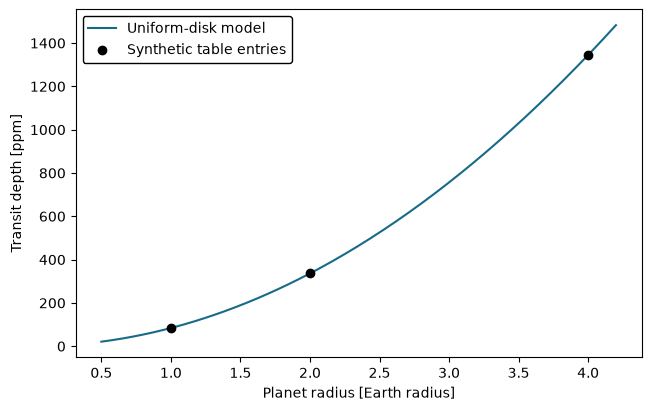

In [5]:
import matplotlib.pyplot as plt
from tdpy.plotting import configure_plot_style, show_figures

typeplotback = 'white'
configure_plot_style(typeplotback)

radius_grid = np.linspace(0.5, 4.2, 200) * u.R_earth  # [R_earth]
depth_grid_ppm = 1e6 * (radius_grid / stellar_radius).to_value(u.dimensionless_unscaled)**2
figure, axis = plt.subplots(figsize=(6.4, 4.0), constrained_layout=True)
axis.plot(radius_grid.to_value(u.R_earth), depth_grid_ppm,
          color="#176B87", label="Uniform-disk model")
axis.scatter(planets["radius"].to_value(u.R_earth), planets["depth_ppm"],
             color="black" if typeplotback == 'white' else "white",
             label="Synthetic table entries", zorder=3)
axis.set(xlabel="Planet radius [Earth radius]", ylabel="Transit depth [ppm]")
axis.grid(False)
axis.legend(frameon=True, fancybox=True, framealpha=1.0)
show_figures(typeplotback=typeplotback)

## Your Turn

1. Add a synthetic planet with three Earth radii orbiting a star with half the Sun's radius. Keep the units attached until the final dimensionless ratio. What depth do you predict in ppm? Explain why it is nine times the depth of our two-Earth-radius planet around the Sun-sized host.
2. A synthetic transit has depth $100\pm10$ ppm around a star with radius $0.8\pm0.04$ solar radii. Infer the planet radius. For small independent errors, use

$$
\left(\frac{\sigma_{R_p}}{R_p}\right)^2 = \left(\frac{\sigma_{R_\star}}{R_\star}\right)^2 + \frac14\left(\frac{\sigma_\delta}{\delta}\right)^2.
$$

Which two uncertainty contributions are equal here? What additional assumptions would be needed for correlated errors or a grazing transit?
3. Convert `schedule["elapsed"]` to seconds without changing its physical meaning. Explain why dividing a Julian Date by 24 would not be the corresponding operation on an absolute timestamp.

### Check Your Reasoning

The first depth is about 3,000 ppm. The second radius is about $0.87\pm0.06$ Earth radii under the stated independent-error approximation. The host-radius and depth terms each contribute a 5% fractional radius uncertainty. The UTC interval contains a leap second, so two elapsed seconds separate the two displayed instants.

## Take It Further

Use a `QTable` for quantities with physical units, preserve the provenance of the actual input data, and state the time scale before comparing timestamps. Unit compatibility catches dimensional mistakes; it cannot establish that an assumed model describes a real observation.

The [Astropy units guide](https://docs.astropy.org/en/stable/units/index.html), [quantity-aware tables](https://docs.astropy.org/en/stable/table/mixin_columns.html), and [time guide](https://docs.astropy.org/en/stable/time/index.html) explain the APIs used here. Continue with [pandas](Pandas.ipynb) to compare tabular representations or return to the [curriculum](../ExoCore.ipynb).